# RSA-896: conferir é barato, fatorar é caro

**Palestra:** *Uma década quântica na nuvem e a contagem regressiva da criptografia* · IBM Qiskit Fall Fest Brasil 2026 (slide 5)
**Autor:** Jullyano Lino

> **Leia antes de rodar:** este notebook **não** quebra RSA, **não** usa computador quântico e **não** executa o algoritmo de Shor. Ele faz o que qualquer pessoa pode fazer com um notebook: **conferir** que $p\times q=N$ para o número RSA-896 e, com isso, sentir a **assimetria** entre *verificar* uma fatoração (milissegundos) e *encontrá-la* (dezenas de anos-GPU). A fatoração de RSA-896 foi feita **por métodos clássicos** (GNFS) e **não afeta chaves RSA-2048** em uso.

## O que você vai fazer
1. Conferir o par de fatores de RSA-896 (produto, tamanhos, primalidade) e **medir o tempo** da conferência.
2. Validar suas funções num **teste de resposta conhecida** (RSA-100) e rejeitar um par errado.
3. Ver o **custo de fatorar** crescer com o tamanho: medições reais com $\rho$ de Pollard em módulos pequenos e uma **extrapolação heurística** (rotulada como tal) do crivo de corpo de números (GNFS).
4. Ver a parte clássica do algoritmo de **Shor** (do período à fatoração) e entender **o que o computador quântico faria** e o que não faz hoje.
5. Treinar com exercícios (gabaritos no fim).

**Não precisa de conta IBM, token ou hardware.** Tempo total: menos de 2 minutos.

## Sumário
1. Dados e fontes · 2. Conferindo p × q · 3. Teste de resposta conhecida (RSA-100) · 4. RSA de brinquedo · 5. Quanto custa fatorar? · 6. A parte clássica do Shor · 7. Exercícios · 8. Gabaritos · 9. Fontes

In [1]:
import math, time, random, statistics
import numpy as np
import matplotlib.pyplot as plt

## 1. Dados e fontes

O anúncio da fatoração é de **Stephen A. Weis** (19/09/2026): GNFS (*General Number Field Sieve*) com o CADO-NFS portado para GPU com ajuda do Claude, até **2.048 GPUs** em tempo ocioso, cerca de **10 dias** e **~30 anos-GPU**; o autor afirma que o resultado **não acelerou o GNFS de forma relevante** e **não afeta o RSA-2048** [F1]. O resumo em veículo independente confere tamanho e método [F2].

**Como tratamos os números:** copiamos N, p e q do anúncio [F1] e **não confiamos na cópia**: a seção 2 verifica por conta própria o produto, a primalidade e os tamanhos. Se um dígito estivesse errado, o produto não bateria.

In [2]:
# RSA-896 (desafio RSA Factoring Challenge) e fatores publicados por S. A. Weis, 19/09/2026 [F1]
N_896 = 412023436986659543855531365332575948179811699844327982845455626433876445565248426198098870423161841879261420247188869492560931776375033421130982397485150944909106910269861031862704114880866970564902903653658867433731720813104105190864254793282601391257624033946373269391
P_896 = 636606729769440499166579950236036751749912014371509557713570027508971809534551913252252094954941974952859310861988904737359709200557919
Q_896 = 647218161102195448058768698177623951380616936266986989243011933572862870905830904361851542450154852431416136790787107595965374752513489

## 2. Conferindo $p\times q = N$

Três verificações, todas baratas:
1. $p\times q = N$ (aritmética exata de inteiros de precisão arbitrária do Python);
2. tamanhos: 270 dígitos decimais / 896 bits para $N$; 135 dígitos / 448 bits para cada primo;
3. $p$ e $q$ são **primos prováveis** pelo teste de **Miller–Rabin**. Com $k$ bases aleatórias, a probabilidade de um composto passar é no máximo $4^{-k}$ [F3]. Aqui $k=40$ ($<10^{-24}$). É um teste **probabilístico**, não uma prova de primalidade (para uma prova existem certificados, como ECPP; ver exercício 6).

Note o que a conferência **prova** e o que **não** prova: ela prova que *estes* $p$ e $q$ multiplicam para *este* $N$. Que $N$ seja de fato o RSA-896 do desafio depende da fonte do número [F1]; aqui o tamanho e o valor foram conferidos contra o anúncio, não contra o arquivo original da RSA Labs.

In [3]:
def is_probable_prime(n, k=40, rng=None):
    """Miller-Rabin. Erro <= 4**-k para composto. Determinístico para n < 3.3e24 com as 13 primeiras bases primas."""
    if n < 2: return False
    small = (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41)
    for p in small:
        if n % p == 0: return n == p
    d, s = n - 1, 0
    while d % 2 == 0: d //= 2; s += 1
    rng = rng or random.Random(0)
    bases = list(small) if n < 3_317_044_064_679_887_385_961_981 else [rng.randrange(2, n - 1) for _ in range(k)]
    for a in bases:
        x = pow(a, d, n)
        if x in (1, n - 1): continue
        for _ in range(s - 1):
            x = x * x % n
            if x == n - 1: break
        else:
            return False
    return True

def verify_factorization(n, p, q):
    """True se 1 < p <= q < n, p*q == n e ambos primos prováveis."""
    return 1 < p <= q < n and p * q == n and is_probable_prime(p) and is_probable_prime(q)

# sanidade da função de primalidade
assert [x for x in range(2, 60) if is_probable_prime(x)] == [2,3,5,7,11,13,17,19,23,29,31,37,41,43,47,53,59]
assert not is_probable_prime(561)          # número de Carmichael: engana o teste de Fermat, não o de Miller-Rabin
assert is_probable_prime(2**127 - 1)       # primo de Mersenne
print("Miller-Rabin: ok")

Miller-Rabin: ok


In [4]:
t0 = time.perf_counter()
ok_product = (P_896 * Q_896 == N_896)
t_prod = time.perf_counter() - t0
t0 = time.perf_counter()
ok_all = verify_factorization(N_896, P_896, Q_896)
t_all = time.perf_counter() - t0

print("p * q == N:", ok_product, f"  ({t_prod*1e6:.1f} microssegundos)")
print("N: ", len(str(N_896)), "dígitos,", N_896.bit_length(), "bits")
print("p: ", len(str(P_896)), "dígitos,", P_896.bit_length(), "bits   q:", len(str(Q_896)), "dígitos,", Q_896.bit_length(), "bits")
print("p e q primos prováveis (Miller-Rabin, 40 bases):", is_probable_prime(P_896), is_probable_prime(Q_896))
print(f"verificação completa: {ok_all}  ({t_all*1e3:.2f} ms)")

assert ok_product and ok_all
assert (len(str(N_896)), N_896.bit_length()) == (270, 896)
assert (P_896.bit_length(), Q_896.bit_length()) == (448, 448) and (len(str(P_896)), len(str(Q_896))) == (135, 135)
assert P_896 < Q_896

p * q == N: True   (471.8 microssegundos)
N:  270 dígitos, 896 bits
p:  135 dígitos, 448 bits   q: 135 dígitos, 448 bits
p e q primos prováveis (Miller-Rabin, 40 bases): True True
verificação completa: True  (55.20 ms)


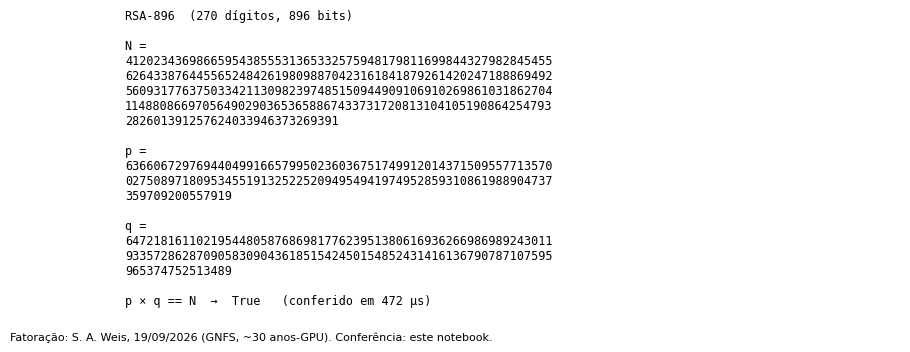

In [5]:
# Imagem para o slide 5: a conferência numa tela (dígitos agrupados)
def wrap(s, w=60): return "\n".join(s[i:i+w] for i in range(0, len(s), w))
fig, ax = plt.subplots(figsize=(10, 3.8)); ax.axis("off")
txt = ("RSA-896  (270 dígitos, 896 bits)\n\nN =\n" + wrap(str(N_896)) + "\n\np =\n" + wrap(str(P_896)) +
       "\n\nq =\n" + wrap(str(Q_896)) + f"\n\np × q == N  →  {ok_product}   (conferido em {t_prod*1e6:.0f} µs)")
ax.text(0.0, 1.0, txt, family="monospace", fontsize=8.5, va="top")
fig.text(0.01, 0.01, "Fatoração: S. A. Weis, 19/09/2026 (GNFS, ~30 anos-GPU). Conferência: este notebook.", fontsize=8)
fig.savefig("rsa896_conferencia.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Teste de resposta conhecida: RSA-100
RSA-100 (100 dígitos, 330 bits) foi fatorado em 1991. Usá-lo como **caso de teste** mostra que as funções funcionam em outro número e que **rejeitam** um par errado: se o código aceitasse tudo, a conferência de RSA-896 não significaria nada. Os valores abaixo são do desafio RSA clássico; o próprio produto $p\times q=N$ serve de verificação cruzada (um dígito trocado quebraria a igualdade).

In [6]:
N100 = 1522605027922533360535618378132637429718068114961380688657908494580122963258952897654000350692006139
P100 = 37975227936943673922808872755445627854565536638199
Q100 = 40094690950920881030683735292761468389214899724061

assert verify_factorization(N100, P100, Q100)
assert (len(str(N100)), N100.bit_length()) == (100, 330)
# controles negativos: tudo isso tem de ser REJEITADO
assert not verify_factorization(N100, P100, Q100 + 2)                 # fator errado
assert not verify_factorization(N100, Q100, P100)                     # ordem trocada (exigimos p <= q)
assert not verify_factorization(N_896, P_896, Q_896 + 2)
assert not verify_factorization(N_896, P_896 + 1, Q_896 - 1)          # soma preservada, produto não
assert not verify_factorization(N_896, 1, N_896)                      # fatoração trivial
print("RSA-100 aceito; pares errados rejeitados: ok")

RSA-100 aceito; pares errados rejeitados: ok


## 4. RSA de brinquedo (para ver a chave quebrar)
RSA "de livro-texto": escolha primos $p,q$; $n=pq$; $\varphi=(p-1)(q-1)$; $e=65537$; $d=e^{-1}\bmod\varphi$. Cifrar: $c=m^e\bmod n$; decifrar: $m=c^d\bmod n$. A segurança vem de **fatorar $n$ ser difícil**: quem fatora $n$ recalcula $d$.

> **Aviso:** RSA sem preenchimento (*padding*, como OAEP) **é inseguro** mesmo com chaves grandes. Isto é didático.

In [7]:
def gen_prime(bits, rng):
    while True:
        c = rng.getrandbits(bits) | (1 << (bits - 1)) | 1
        if is_probable_prime(c, rng=rng): return c

def make_toy_rsa(bits, seed, e=65537):
    rng = random.Random(seed)
    while True:
        p, q = gen_prime(bits // 2, rng), gen_prime(bits // 2, rng)
        if p == q: continue
        phi = (p - 1) * (q - 1)
        if math.gcd(e, phi) == 1:
            return dict(n=p * q, e=e, d=pow(e, -1, phi), p=min(p, q), q=max(p, q))

key = make_toy_rsa(64, seed=7)
m = 123456789
c = pow(m, key["e"], key["n"])
print("n =", key["n"], f"({key['n'].bit_length()} bits)   cifrado c =", c, "  decifrado:", pow(c, key["d"], key["n"]))
assert pow(c, key["d"], key["n"]) == m

n = 9583642333108370353 (64 bits)   cifrado c = 7868178196118001194   decifrado: 123456789


## 5. Quanto custa fatorar?

### 5.1 Medição real: $\rho$ de Pollard em módulos pequenos
O método $\rho$ de Pollard (variante de Brent) acha um fator $p$ em cerca de $\sqrt p$ passos, ou seja, $\approx 2^{b/4}$ para um módulo de $b$ bits com dois primos de $b/2$ bits [F4]. O tempo **dobra** a cada ~4 bits a mais no módulo. Os tempos abaixo dependem da sua máquina; o que importa é a **forma** da curva.

 40 bits:      1.10 ms
 48 bits:      2.98 ms
 56 bits:     10.72 ms
 64 bits:     48.11 ms
 72 bits:    400.58 ms
 80 bits:   1037.57 ms
inclinação de log2(tempo) por bit: 0.26   (teoria ~ 0,25; medição ruidosa)


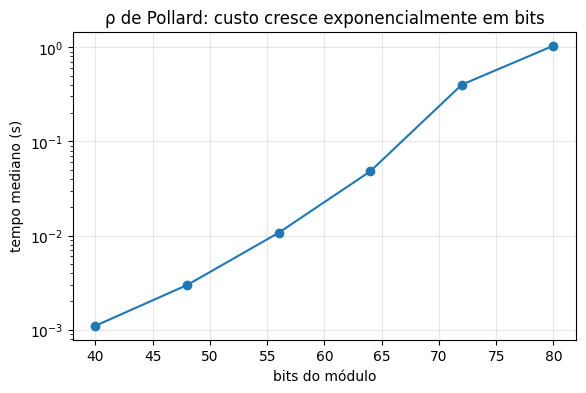

In [8]:
def pollard_rho_brent(n, seed=1):
    if n % 2 == 0: return 2
    rng = random.Random(seed)
    while True:
        c = rng.randrange(1, n); y = rng.randrange(0, n); m = 128
        g = r = q = 1
        while g == 1:
            x = y
            for _ in range(r): y = (y * y + c) % n
            k = 0
            while k < r and g == 1:
                ys = y
                for _ in range(min(m, r - k)):
                    y = (y * y + c) % n
                    q = q * abs(x - y) % n
                g = math.gcd(q, n); k += m
            r *= 2
        if g == n:
            g = 1
            while g == 1:
                ys = (ys * ys + c) % n
                g = math.gcd(abs(x - ys), n)
        if g != n: return g

def time_factor(bits, trials, seed0=100):
    ts = []
    for t in range(trials):
        k = make_toy_rsa(bits, seed=seed0 + t)
        t0 = time.perf_counter(); f = pollard_rho_brent(k["n"], seed=t + 1); ts.append(time.perf_counter() - t0)
        assert f in (k["p"], k["q"]), "rho devolveu algo que não é fator"
    return statistics.median(ts)

BITS = [40, 48, 56, 64, 72, 80]
times = [time_factor(b, trials=5 if b < 72 else 3) for b in BITS]
for b, t in zip(BITS, times): print(f"{b:3d} bits: {t*1e3:9.2f} ms")
slope = np.polyfit(BITS, np.log2(times), 1)[0]
print(f"inclinação de log2(tempo) por bit: {slope:.2f}   (teoria ~ 0,25; medição ruidosa)")
fig, ax = plt.subplots(figsize=(6.5, 4)); ax.semilogy(BITS, times, "o-"); ax.set_xlabel("bits do módulo"); ax.set_ylabel("tempo mediano (s)")
ax.set_title("ρ de Pollard: custo cresce exponencialmente em bits"); ax.grid(alpha=.3); plt.show()

### 5.2 Extrapolação **heurística** para GNFS (ordem de grandeza, não previsão)
Para módulos grandes o melhor método clássico conhecido é o GNFS, com custo heurístico subexponencial
$$L_N\big[\tfrac13,\,c\big]=\exp\!\Big(\big(c+o(1)\big)(\ln N)^{1/3}(\ln\ln N)^{2/3}\Big),\qquad c=\big(\tfrac{64}{9}\big)^{1/3}\approx 1{,}923 .$$
Ignorando o $o(1)$ e **calibrando em RSA-896 = 30 anos-GPU** [F1], estimamos a razão de custo para outros tamanhos. **Ressalvas importantes:** (i) o termo $o(1)$ não é desprezível nessa faixa; (ii) o custo real depende de memória e de álgebra linear em grande escala, que não escalam como a fórmula; (iii) um só ponto de calibração; (iv) o resultado de Weis é *um* dado, em hardware específico. Leia a saída como **"muito mais caro, em ordens de grandeza"**, não como número a citar.

In [9]:
def gnfs_L(bits):
    ln_n = bits * math.log(2)
    return math.exp((64/9) ** (1/3) * ln_n ** (1/3) * math.log(ln_n) ** (2/3))

CAL_BITS, CAL_GPU_YEARS = 896, 30.0     # calibração: [F1]
for b in (768, 896, 1024, 2048, 3072):
    ratio = gnfs_L(b) / gnfs_L(CAL_BITS)
    print(f"RSA-{b:<5d}: custo relativo a RSA-896 ≈ {ratio:12.3g}   → ≈ {ratio*CAL_GPU_YEARS:10.3g} anos-GPU (heurístico)")
assert abs(gnfs_L(896) / gnfs_L(896) - 1) < 1e-12
assert gnfs_L(1024) > gnfs_L(896) and gnfs_L(2048) > gnfs_L(1024)

RSA-768  : custo relativo a RSA-896 ≈       0.0246   → ≈      0.737 anos-GPU (heurístico)
RSA-896  : custo relativo a RSA-896 ≈            1   → ≈         30 anos-GPU (heurístico)
RSA-1024 : custo relativo a RSA-896 ≈           30   → ≈        900 anos-GPU (heurístico)
RSA-2048 : custo relativo a RSA-896 ≈     3.49e+10   → ≈   1.05e+12 anos-GPU (heurístico)
RSA-3072 : custo relativo a RSA-896 ≈     1.32e+17   → ≈   3.97e+18 anos-GPU (heurístico)


## 6. A parte clássica do algoritmo de Shor
O algoritmo de Shor fatora $N$ assim: escolhe $a$ coprimo com $N$; encontra a **ordem** $r$ de $a$ módulo $N$ (o menor $r>0$ com $a^r\equiv1$); se $r$ é par e $a^{r/2}\not\equiv-1$, então $\gcd(a^{r/2}\pm1,\,N)$ dá fatores não triviais [F5]. **Só a busca da ordem $r$ é feita no computador quântico** (estimação de fase com exponenciação modular). Todo o resto é aritmética clássica.

Abaixo, a busca de ordem é feita **por força bruta clássica**, só para você ver o pós-processamento funcionar em $N$ pequeno. **Isto não é Shor:** a força bruta custa tempo exponencial em $\log N$, que é exatamente o custo que o hardware quântico (tolerante a falhas) removeria. Hoje não existe máquina capaz de rodar Shor em $N$ criptograficamente relevante; estimativas de recursos para RSA-2048 estão na literatura [F6].

In [10]:
def order(a, n):
    """Menor r > 0 com a**r = 1 (mod n). Força bruta: só para n pequeno."""
    assert math.gcd(a, n) == 1
    x, r = a % n, 1
    while x != 1:
        x = x * a % n; r += 1
    return r

def shor_postprocess(a, n):
    """Dado a coprimo com n, devolve (r, fator) ou (r, None) se esta escolha de a falhar."""
    r = order(a, n)
    if r % 2: return r, None
    y = pow(a, r // 2, n)
    if y == n - 1: return r, None
    f = math.gcd(y - 1, n)
    return (r, f) if 1 < f < n else (r, None)

for n in (15, 21, 35, 91):
    row = []
    for a in range(2, n):
        if math.gcd(a, n) != 1: continue
        r, f = shor_postprocess(a, n)
        row.append((a, r, f))
        assert f is None or (1 < f < n and n % f == 0)
    good = [(a, r, f) for a, r, f in row if f]
    print(f"N={n}: {len(good)}/{len(row)} escolhas de a dão fator; exemplo a={good[0][0]} (r={good[0][1]}) → {good[0][2]} × {n // good[0][2]}")

N=15: 6/7 escolhas de a dão fator; exemplo a=2 (r=4) → 3 × 5
N=21: 6/11 escolhas de a dão fator; exemplo a=2 (r=6) → 7 × 3
N=35: 18/23 escolhas de a dão fator; exemplo a=2 (r=12) → 7 × 5
N=91: 54/71 escolhas de a dão fator; exemplo a=2 (r=12) → 7 × 13


## 7. Exercícios
Cada exercício tem verificação automática: imprime "pendente" até você implementar. Soluções na seção 8.

**Exercício 1 · Método novo.** Implemente `trial_division(n, limit)` (divisões por 2, depois ímpares até `limit`) que devolve o menor fator ou `None`. Fatore o `N` do `make_toy_rsa(40, ...)`. **Pergunta:** qual seria o número de divisões necessárias para RSA-896 com $p\approx 2^{448}$? Compare com o número de átomos no universo observável (~$10^{80}$).

**Exercício 2 · Parâmetros.** Em `time_factor`, troque `BITS` por `[32, 40, 48, 56, 64, 72, 80, 88]` e ajuste uma reta a $\log_2(\text{tempo})$. A inclinação ficou perto de 0,25? Por que a medição é ruidosa (dica: o número de passos do $\rho$ é aleatório)?

**Exercício 3 · Método novo (Fermat).** Implemente `fermat_factor(n)`: procure $a\ge\lceil\sqrt n\rceil$ tal que $a^2-n$ seja quadrado perfeito $b^2$; então $n=(a-b)(a+b)$. Teste com **primos próximos** ($q=\text{nextprime}(p+2^{20})$, $p$ de 256 bits) e com um RSA de brinquedo normal. **Pergunta:** o que isso ensina sobre como gerar $p$ e $q$?

**Exercício 4 · Parâmetros do Shor clássico.** Para $N=21,35,91,221$: qual fração das escolhas de $a$ coprimas produz fator? Compare com a previsão "pelo menos metade" (para $N$ ímpar com dois fatores primos distintos, a probabilidade de uma escolha aleatória de $a$ funcionar é ≥ ½ [F5]).

**Exercício 5 · Robustez.** Escreva `verify_factorization_strict(n, p, q)` que também rejeita $p=q$ e exige `p, q` com o mesmo número de bits (como no RSA-896). Teste nos casos RSA-100, RSA-896 e num par com bits diferentes.

**Exercício 6 · Pesquisa e conceito.** (a) O Miller–Rabin é probabilístico. Pesquise o que é um *certificado de primalidade* (ex.: ECPP) e por que ele tornaria a verificação do RSA-896 uma **prova**. (b) Por que a fatoração de RSA-896 por GNFS não ameaça RSA-2048, mas é um lembrete para chaves de 1024 bits?

In [11]:
# --- Exercício 1 ---
def trial_division(n, limit):
    # TODO
    return None

k40 = make_toy_rsa(40, seed=11)
f = trial_division(k40["n"], 2**21)
print("Exercício 1:", "pendente" if f is None else ("OK" if f == k40["p"] else f"revise ({f})"))

Exercício 1: pendente


In [12]:
# --- Exercício 3 ---
def fermat_factor(n):
    # TODO: devolva (p, q) com p*q == n
    return None

r = fermat_factor(8051)       # 8051 = 83 * 97
print("Exercício 3:", "pendente" if r is None else ("OK" if r == (83, 97) else f"revise ({r})"))

Exercício 3: pendente


In [13]:
# --- Exercício 4 ---
def fraction_good_a(n):
    # TODO: use shor_postprocess; devolva fração de a coprimos (2 <= a < n) que dão fator
    return None

print("Exercício 4:", "pendente" if fraction_good_a(21) is None else {n: round(fraction_good_a(n), 3) for n in (21, 35, 91, 221)})

Exercício 4: pendente


In [14]:
# --- Exercício 5 ---
def verify_factorization_strict(n, p, q):
    # TODO
    return None

print("Exercício 5:", "pendente" if verify_factorization_strict(N100, P100, Q100) is None else
      [verify_factorization_strict(N100, P100, Q100), verify_factorization_strict(N_896, P_896, Q_896)])

Exercício 5: pendente


## 8. Gabaritos
Células recolhidas (formulário do Colab). Tente antes de abrir.

In [15]:
#@title Gabarito 1
def trial_division_sol(n, limit):
    if n % 2 == 0: return 2
    d = 3
    while d <= limit:
        if n % d == 0: return d
        d += 2
    return None

k40 = make_toy_rsa(40, seed=11)
f = trial_division_sol(k40["n"], 2**21)
print("fator:", f, f == k40["p"])
# Número de divisões para p ~ 2**448 (só ímpares): ~ 2**447 ≈ 10**134,6, contra ~10**80 átomos no universo observável.
print("log10(2**447) =", round(447 * math.log10(2), 1))
assert f == k40["p"]

fator: 819167 True
log10(2**447) = 134.6


In [16]:
#@title Gabarito 3
def fermat_factor_sol(n):
    a = math.isqrt(n)
    if a * a < n: a += 1
    while True:
        b2 = a * a - n
        b = math.isqrt(b2)
        if b * b == b2: return a - b, a + b
        a += 1

assert fermat_factor_sol(8051) == (83, 97)
rng = random.Random(5)
p = gen_prime(256, rng)
q = p + 2**20
while not is_probable_prime(q): q += 2
t0 = time.perf_counter(); r = fermat_factor_sol(p * q); dt = time.perf_counter() - t0
print("primos próximos (256 bits): fatorado em", f"{dt*1e3:.1f} ms;", r == (p, q))
# Um módulo de brinquedo "normal" (64 bits, p e q independentes) levaria ~2**32 passos em Fermat: não rodamos.
# Lição: p e q não podem ser próximos; padrões de geração de chaves exigem |p - q| grande.
assert r == (p, q)

primos próximos (256 bits): fatorado em 0.1 ms; True


In [17]:
#@title Gabarito 4
def fraction_good_a_sol(n):
    cop = [a for a in range(2, n) if math.gcd(a, n) == 1]
    return sum(1 for a in cop if shor_postprocess(a, n)[1]) / len(cop)

res = {n: fraction_good_a_sol(n) for n in (21, 35, 91, 221)}
print({k: round(v, 3) for k, v in res.items()})
assert all(v >= 0.5 for v in res.values())          # N = produto de dois primos ímpares distintos

{21: 0.545, 35: 0.783, 91: 0.761, 221: 0.911}


In [18]:
#@title Gabarito 5
def verify_factorization_strict_sol(n, p, q):
    return p != q and p.bit_length() == q.bit_length() and verify_factorization(n, min(p, q), max(p, q))

assert verify_factorization_strict_sol(N100, P100, Q100) and verify_factorization_strict_sol(N_896, P_896, Q_896)
assert not verify_factorization_strict_sol(3 * 1000003, 3, 1000003)      # primos com número de bits diferente
print("ok")

ok


**Exercício 6 (resposta curta):** (a) Certificados de primalidade (ECPP, Pratt) permitem verificar a primalidade de modo **determinístico e rápido**, sem depender de bases aleatórias; a verificação do certificado é barata, assim como a de $p\times q=N$. (b) Para RSA-896 o GNFS custou ~30 anos-GPU em 2026; pela escala da seção 5.2, RSA-2048 custa **ordens de grandeza** mais (e a escala real é pior que a heurística por causa de memória e álgebra linear), logo está fora de alcance clássico. Já chaves de 1024 bits ficam, pela mesma heurística, em cerca de **30×** o custo de RSA-896, e o próprio autor argumenta que estão ao alcance de atores com grandes frotas de GPU [F1]. O risco **quântico** (Shor) é outro: ele não depende de GNFS, mas de máquinas tolerantes a falhas que ainda não existem [F6].

## 9. Fontes
✔ = página aberta e conferida nesta sessão de produção. Os demais itens são referências clássicas que **não foram reabertas**; confira antes de citar em publicação.

| Ref. | Fonte | Verificada |
|---|---|---|
| [F1] | S. A. Weis, *RSA-896* (anúncio da fatoração, set/2026): https://saweis.net/posts/rsa-896.html | ✔ (N, p, q, método, recursos); produto e primalidade reconferidos por código |
| [F2] | *RSA-896 Factored with Claude on GPUs*, PostQuantum.com: https://postquantum.com/security-pqc/rsa-896-factored-claude-gpus/ | ✔ (tamanhos e método) |
| [F3] | M. O. Rabin, *Probabilistic algorithm for testing primality*, J. Number Theory 12 (1980) 128–138; G. L. Miller, J. Comput. Syst. Sci. 13 (1976) 300–317 | não reaberta |
| [F4] | J. M. Pollard, *A Monte Carlo method for factorization*, BIT 15 (1975) 331–334; R. P. Brent, *An improved Monte Carlo factorization algorithm*, BIT 20 (1980) 176–184 | não reaberta |
| [F5] | P. W. Shor, *Polynomial-time algorithms for prime factorization and discrete logarithms on a quantum computer*, SIAM J. Comput. 26 (1997) 1484–1509; arXiv:quant-ph/9508027 | não reaberta |
| [F6] | C. Gidney, *How to factor 2048 bit RSA integers with less than a million noisy qubits*, arXiv:2505.15917 (2025) | não reaberta |
| [F7] | RSA-100 (RSA Factoring Challenge): valores conferidos pelo produto p × q = N (verificação aritmética no notebook) | verificação aritmética |

**Reprodutibilidade:** o notebook foi **executado de ponta a ponta** antes da entrega. Os tempos da seção 5.1 variam com a máquina.